# Flappy Bird AI — Level 5 Model Evaluation

**Paired evaluation:** baseline NEAT model vs. progressive-training model.

This notebook analyzes the 100-seed comparison exported by `evaluate_progressive.py`. It is designed to run locally in **VS Code** with the project's Python virtual environment.

### Before running
- Keep this notebook in the **FlappyBirdAI project root** (beside `play.py`).
- Make sure `results/level_5_comparison.csv` exists.
- Select the project's `.venv` Python interpreter in VS Code.
- Run the cells from top to bottom.

No Google Colab upload step is needed.


## 1. Imports and configuration

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Notebook is expected to be in the FlappyBirdAI project root.
PROJECT_DIR = Path.cwd()
CSV_PATH = PROJECT_DIR / "results" / "level_5_comparison.csv"

print(f"Project directory: {PROJECT_DIR}")
print(f"CSV file: {CSV_PATH}")
print(f"CSV exists: {CSV_PATH.exists()}")


Matplotlib is building the font cache; this may take a moment.


Project directory: /mnt/data2/AI model/FlappyBirdAI
CSV file: /mnt/data2/AI model/FlappyBirdAI/results/level_5_comparison.csv
CSV exists: True


## 2. Load and validate the evaluation data

In [4]:
if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_PATH}. "
        "Place this notebook in the FlappyBirdAI project root and check the results folder."
    )

df = pd.read_csv(CSV_PATH)

required_columns = {
    "seed",
    "baseline_score",
    "progressive_score",
    "baseline_frames",
    "progressive_frames",
    "winner",
}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {sorted(missing)}")

df = df.sort_values("seed").reset_index(drop=True)
df["score_difference"] = df["progressive_score"] - df["baseline_score"]
df["time_difference_seconds"] = (
    df["progressive_frames"] - df["baseline_frames"]
) / 60

print(f"Paired test runs: {len(df)}")
display(df.head())


Paired test runs: 100


,seed,baseline_score,progressive_score,baseline_frames,progressive_frames,winner,score_difference,time_difference_seconds
0,2000,68,49,2700,1975,baseline,-19,-12.083333
1,2001,35,66,1470,2700,progressive,31,20.500000
2,2002,32,66,1381,2700,progressive,34,21.983333
3,2003,65,65,2700,2700,tie,0,0.000000
4,2004,50,50,2056,2056,tie,0,0.000000


## 3. Executive summary

In [5]:
summary = pd.DataFrame({
    "Metric": [
        "Test runs",
        "Baseline average pipes",
        "Progressive average pipes",
        "Average improvement (pipes)",
        "Relative average improvement",
        "Baseline standard deviation",
        "Progressive standard deviation",
        "Progressive wins",
        "Baseline wins",
        "Ties",
    ],
    "Result": [
        len(df),
        df["baseline_score"].mean(),
        df["progressive_score"].mean(),
        df["score_difference"].mean(),
        (
            (df["progressive_score"].mean() / df["baseline_score"].mean()) - 1
        ) * 100 if df["baseline_score"].mean() else np.nan,
        df["baseline_score"].std(),
        df["progressive_score"].std(),
        (df["winner"] == "progressive").sum(),
        (df["winner"] == "baseline").sum(),
        (df["winner"] == "tie").sum(),
    ],
})
display(summary)


,Metric,Result
0,Test runs,100.000000
1,Baseline average pipes,33.900000
2,Progressive average pipes,39.030000
3,Average improvement (pipes),5.130000
4,Relative average improvement,15.132743
5,Baseline standard deviation,22.952520
6,Progressive standard deviation,24.773909
7,Progressive wins,31.000000
8,Baseline wins,13.000000
9,Ties,56.000000


## 4. Average score comparison

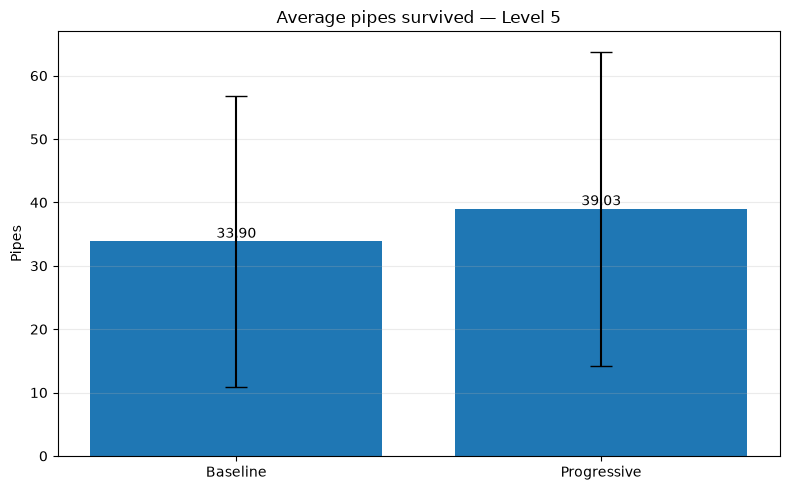

In [6]:
means = [df["baseline_score"].mean(), df["progressive_score"].mean()]
stds = [df["baseline_score"].std(), df["progressive_score"].std()]
labels = ["Baseline", "Progressive"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, means, yerr=stds, capsize=8)
plt.title("Average pipes survived — Level 5")
plt.ylabel("Pipes")
plt.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"{value:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


## 5. Score distributions

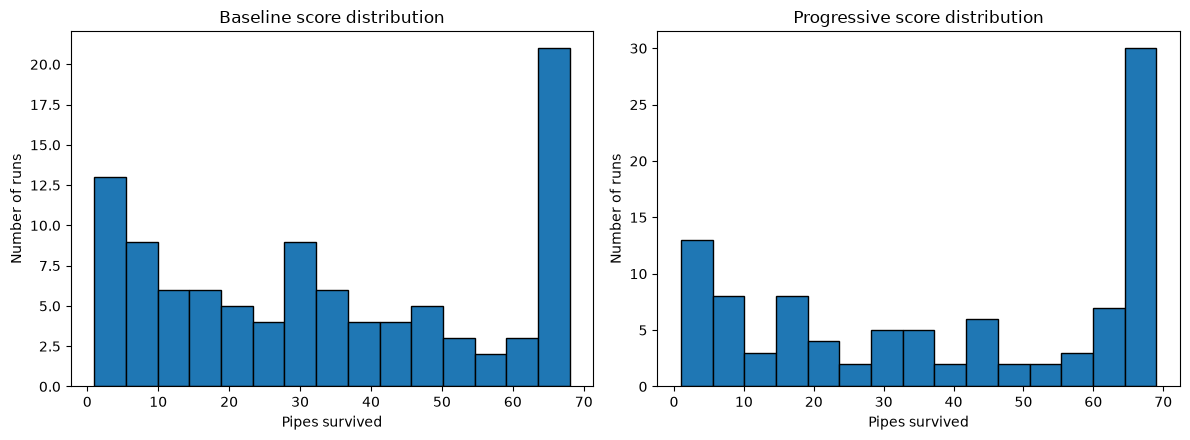

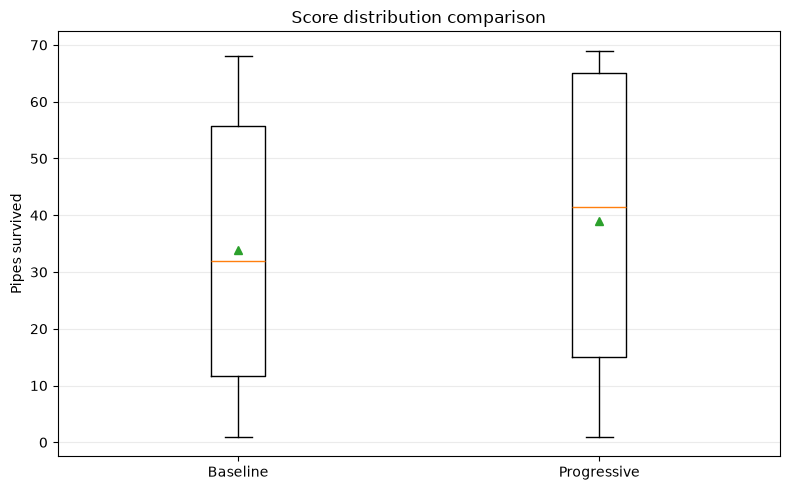

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(df["baseline_score"], bins=15, edgecolor="black")
axes[0].set_title("Baseline score distribution")
axes[0].set_xlabel("Pipes survived")
axes[0].set_ylabel("Number of runs")

axes[1].hist(df["progressive_score"], bins=15, edgecolor="black")
axes[1].set_title("Progressive score distribution")
axes[1].set_xlabel("Pipes survived")
axes[1].set_ylabel("Number of runs")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.boxplot(
    [df["baseline_score"], df["progressive_score"]],
    tick_labels=["Baseline", "Progressive"],
    showmeans=True,
)
plt.title("Score distribution comparison")
plt.ylabel("Pipes survived")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 6. Paired seed-by-seed comparison

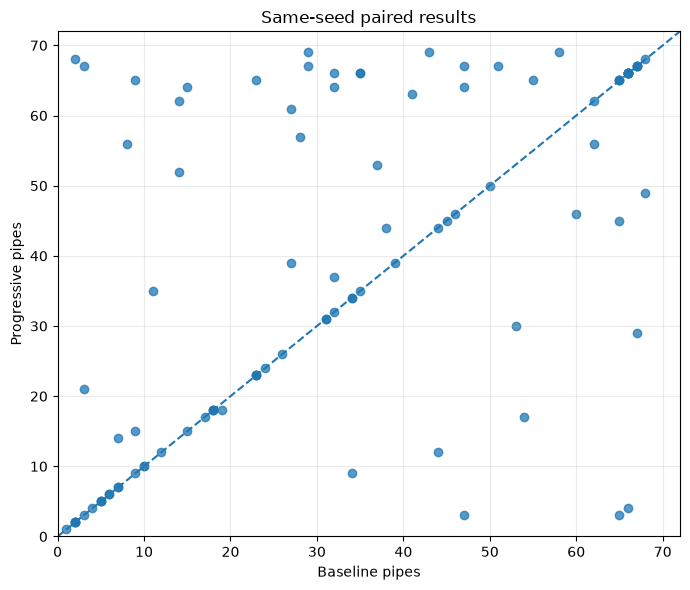

In [8]:
plt.figure(figsize=(7, 6))
plt.scatter(df["baseline_score"], df["progressive_score"], alpha=0.75)
limit = max(df["baseline_score"].max(), df["progressive_score"].max()) + 3
plt.plot([0, limit], [0, limit], linestyle="--")
plt.xlim(0, limit)
plt.ylim(0, limit)
plt.xlabel("Baseline pipes")
plt.ylabel("Progressive pipes")
plt.title("Same-seed paired results")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Per-seed improvement and outcomes

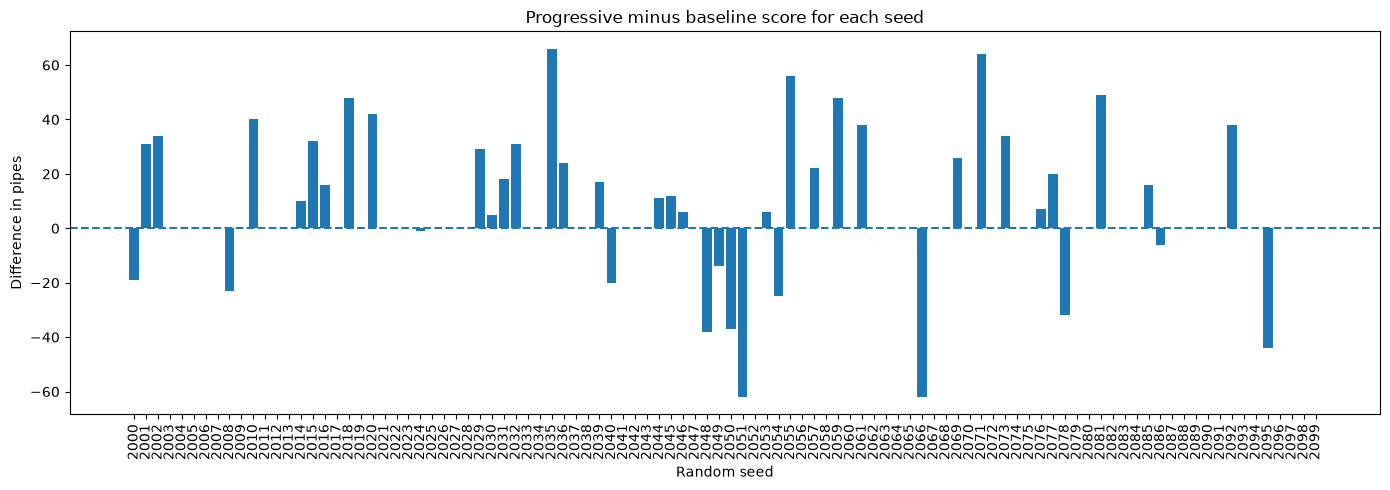

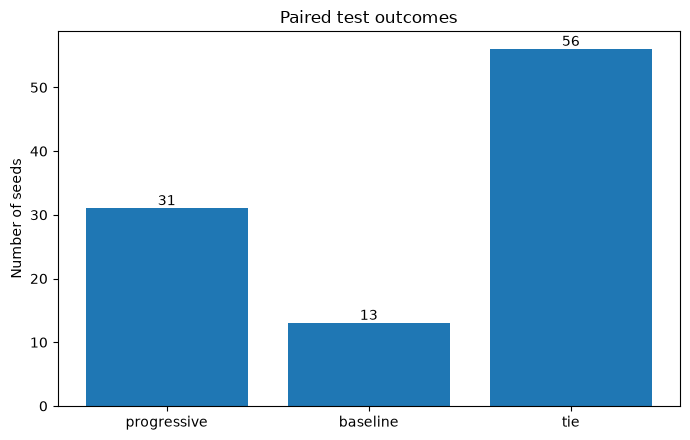

In [9]:
plt.figure(figsize=(14, 5))
plt.bar(df["seed"].astype(str), df["score_difference"])
plt.axhline(0, linestyle="--")
plt.title("Progressive minus baseline score for each seed")
plt.xlabel("Random seed")
plt.ylabel("Difference in pipes")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

outcomes = df["winner"].value_counts().reindex(
    ["progressive", "baseline", "tie"], fill_value=0
)
plt.figure(figsize=(7, 4.5))
plt.bar(outcomes.index, outcomes.values)
plt.title("Paired test outcomes")
plt.ylabel("Number of seeds")
for i, value in enumerate(outcomes.values):
    plt.text(i, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()


## 8. Survival time

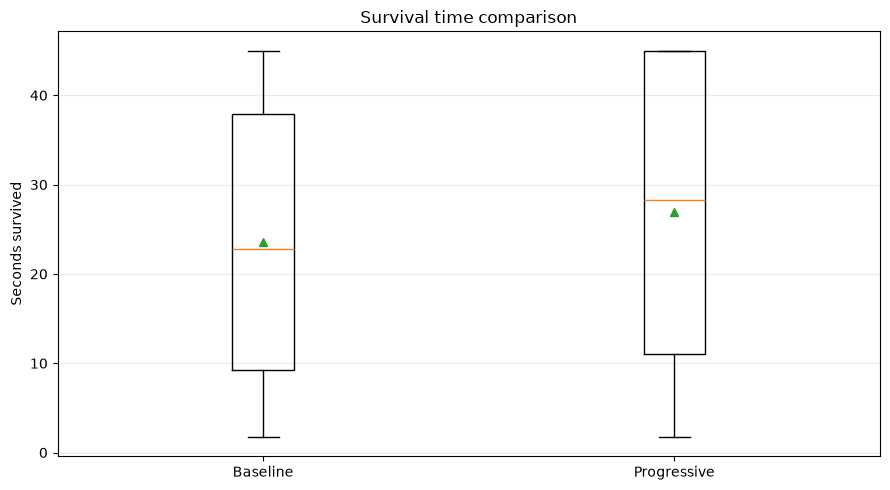

Baseline reached the 45-second evaluation cap: 19/100
Progressive reached the 45-second evaluation cap: 34/100


In [10]:
baseline_seconds = df["baseline_frames"] / 60
progressive_seconds = df["progressive_frames"] / 60

plt.figure(figsize=(9, 5))
plt.boxplot(
    [baseline_seconds, progressive_seconds],
    tick_labels=["Baseline", "Progressive"],
    showmeans=True,
)
plt.title("Survival time comparison")
plt.ylabel("Seconds survived")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

cap_seconds = 45
baseline_cap = int((baseline_seconds >= cap_seconds).sum())
progressive_cap = int((progressive_seconds >= cap_seconds).sum())
print(f"Baseline reached the 45-second evaluation cap: {baseline_cap}/{len(df)}")
print(f"Progressive reached the 45-second evaluation cap: {progressive_cap}/{len(df)}")


## 9. Automatically generated conclusion

In [12]:
baseline_avg = df["baseline_score"].mean()
progressive_avg = df["progressive_score"].mean()
mean_diff = df["score_difference"].mean()
median_diff = df["score_difference"].median()
relative = ((progressive_avg / baseline_avg) - 1) * 100 if baseline_avg else np.nan

progressive_wins = int((df["winner"] == "progressive").sum())
baseline_wins = int((df["winner"] == "baseline").sum())
ties = int((df["winner"] == "tie").sum())

print("LEVEL 5 EVALUATION SUMMARY")
print("=" * 34)
print(f"Paired test runs: {len(df)}")
print(f"Baseline average: {baseline_avg:.2f} pipes")
print(f"Progressive average: {progressive_avg:.2f} pipes")
print(f"Mean paired difference: {mean_diff:+.2f} pipes")
print(f"Median paired difference: {median_diff:+.2f} pipes")
print(f"Relative average change: {relative:+.1f}%")
print()
print(f"Progressive wins: {progressive_wins}")
print(f"Baseline wins: {baseline_wins}")
print(f"Ties: {ties}")

if mean_diff > 0:
    print("\nThe progressive model achieved a higher average score on this test set.")
elif mean_diff < 0:
    print("\nThe baseline model achieved a higher average score on this test set.")
else:
    print("\nBoth models achieved the same average score on this test set.")

print(
    "\nInterpretation: both models were evaluated on the same random seeds, "
    "so this is a paired comparison. These results describe this test set; "
    "they do not by themselves establish statistical significance or prove "
    "that the improvement will generalize to every possible game sequence."
)


LEVEL 5 EVALUATION SUMMARY
Paired test runs: 100
Baseline average: 33.90 pipes
Progressive average: 39.03 pipes
Mean paired difference: +5.13 pipes
Median paired difference: +0.00 pipes
Relative average change: +15.1%

Progressive wins: 31
Baseline wins: 13
Ties: 56

The progressive model achieved a higher average score on this test set.

Interpretation: both models were evaluated on the same random seeds, so this is a paired comparison. These results describe this test set; they do not by themselves establish statistical significance or prove that the improvement will generalize to every possible game sequence.


## Notes and limitations

- Both models are compared on the same test seeds, making the comparison paired.
- Each run is capped at 45 seconds (2,700 frames at 60 FPS).
- The CSV contains evaluation outcomes, not generation-by-generation NEAT training history.
- Do not interpret these evaluation charts as a training fitness curve.
- A higher average on this test set is evidence of better performance on these sampled scenarios, not proof of universal superiority.
